# AIE322 - Advanced Machine Learning
## Practical Assignment: E-Commerce Customer Churn Classification

- **University:** New Mansoura University (NMU), Faculty of Computer Science & Engineering
- **Student:** Belal Mahmoud Hussien
- **Dataset:** E-Commerce Customer Churn Dataset (`E Commerce Dataset.xlsx`, sheet `E Comm`)
- **Target Variable:** `Churn` (`0` = Retained, `1` = Churned)

In this notebook, I build a binary classification pipeline in `scikit-learn` to predict customer churn without data leakage. The notebook is organized into four parts:
1. **Part 1:** Data Cleaning, EDA, and Train/Test Splitting
2. **Part 2:** Preprocessing Pipelines (`ColumnTransformer` and `Pipeline`)
3. **Part 3:** Model Complexity, Bias-Variance Tradeoff, and Regularization
4. **Part 4:** Ensemble Learning (Bagging, Pasting, AdaBoost, and Voting)

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (
    AdaBoostClassifier,
    BaggingClassifier,
    RandomForestClassifier,
    VotingClassifier,
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import learning_curve, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*penalty is deprecated.*")

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (10, 5)

RANDOM_STATE = 42

In [2]:
def load_dataset(excel_path="E Commerce Dataset.xlsx", csv_path="E Commerce Dataset.csv"):
    if Path(excel_path).exists():
        return pd.read_excel(excel_path, sheet_name="E Comm")
    if Path(csv_path).exists():
        return pd.read_csv(csv_path)
    raise FileNotFoundError(f"Dataset not found in {Path.cwd()}")


def evaluate_model(name, model, X_tr, y_tr, X_te, y_te):
    y_train_pred = model.predict(X_tr)
    y_test_pred = model.predict(X_te)

    scores = {
        "Model": name,
        "Train Accuracy": accuracy_score(y_tr, y_train_pred),
        "Test Accuracy": accuracy_score(y_te, y_test_pred),
        "Precision": precision_score(y_te, y_test_pred, zero_division=0),
        "Recall": recall_score(y_te, y_test_pred, zero_division=0),
        "F1-Score": f1_score(y_te, y_test_pred, zero_division=0),
    }
    if hasattr(model, "predict_proba"):
        try:
            y_prob = model.predict_proba(X_te)[:, 1]
            scores["ROC-AUC"] = roc_auc_score(y_te, y_prob)
        except Exception:
            scores["ROC-AUC"] = np.nan
    else:
        scores["ROC-AUC"] = np.nan
    return scores


def make_pipeline(preprocessor, estimator):
    return Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", estimator),
    ])


all_results = []

## Part 1: Data Cleaning, EDA & Reproducible Splitting

### 1.1 Initial Inspection & Cleaning
First, load the `E Comm` sheet from `E Commerce Dataset.xlsx`, drop `CustomerID` since it is just an identifier, check missing values, fix inconsistent category names, remove duplicates, and check numerical features for outliers using IQR.

In [3]:
df_raw = load_dataset()
print("Raw shape:", df_raw.shape)
display(df_raw.head())
df_raw.info()

Raw shape: (5630, 20)


,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,50002,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,50003,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28
3,50004,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07
4,50005,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,129.60


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5630 entries, 0 to 5629
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CustomerID                   5630 non-null   int64  
 1   Churn                        5630 non-null   int64  
 2   Tenure                       5366 non-null   float64
 3   PreferredLoginDevice         5630 non-null   object 
 4   CityTier                     5630 non-null   int64  
 5   WarehouseToHome              5379 non-null   float64
 6   PreferredPaymentMode         5630 non-null   object 
 7   Gender                       5630 non-null   object 
 8   HourSpendOnApp               5375 non-null   float64
 9   NumberOfDeviceRegistered     5630 non-null   int64  
 10  PreferedOrderCat             5630 non-null   object 
 11  SatisfactionScore            5630 non-null   int64  
 12  MaritalStatus                5630 non-null   object 
 13  NumberOfAddress   

In [4]:
# Drop CustomerID
df = df_raw.drop(columns=["CustomerID"]).copy()

# Check missing values
missing_df = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing (%)": (df.isnull().mean() * 100).round(2),
})
display(missing_df[missing_df["Missing Count"] > 0])

# Merge duplicate category spellings
label_fixes = {
    "PreferredLoginDevice": {"Phone": "Mobile Phone"},
    "PreferredPaymentMode": {"CC": "Credit Card", "COD": "Cash on Delivery"},
    "PreferedOrderCat": {"Mobile": "Mobile Phone"},
}
for col, mapping in label_fixes.items():
    before = df[col].unique().tolist()
    df[col] = df[col].replace(mapping)
    after = df[col].unique().tolist()
    print(f"{col}: {before} -> {after}")

# Check duplicates before and after dropping CustomerID
print("\nDuplicates (with CustomerID):   ", df_raw.duplicated().sum())
print("Duplicates (without CustomerID):", df.duplicated().sum())

# Drop exact duplicate rows so identical profiles do not appear in both train and test
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after dropping duplicates:", df.shape)

,Missing Count,Missing (%)
Tenure,264,4.69
WarehouseToHome,251,4.46
HourSpendOnApp,255,4.53
OrderAmountHikeFromlastYear,265,4.71
CouponUsed,256,4.55
OrderCount,258,4.58
DaySinceLastOrder,307,5.45


PreferredLoginDevice: ['Mobile Phone', 'Phone', 'Computer'] -> ['Mobile Phone', 'Computer']
PreferredPaymentMode: ['Debit Card', 'UPI', 'CC', 'Cash on Delivery', 'E wallet', 'COD', 'Credit Card'] -> ['Debit Card', 'UPI', 'Credit Card', 'Cash on Delivery', 'E wallet']
PreferedOrderCat: ['Laptop & Accessory', 'Mobile', 'Mobile Phone', 'Others', 'Fashion', 'Grocery'] -> ['Laptop & Accessory', 'Mobile Phone', 'Others', 'Fashion', 'Grocery']

Duplicates (with CustomerID):    0
Duplicates (without CustomerID): 557
Shape after dropping duplicates: (5073, 19)


In [5]:
# Outlier check using 1.5 * IQR
num_check_cols = [c for c in df.select_dtypes(include=[np.number]).columns if c != "Churn"]
outlier_stats = []
for col in num_check_cols:
    vals = df[col].dropna()
    q1, q3 = vals.quantile(0.25), vals.quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = int(((vals < low) | (vals > high)).sum())
    outlier_stats.append({
        "Feature": col,
        "Min": round(vals.min(), 2),
        "Median": round(vals.median(), 2),
        "Max": round(vals.max(), 2),
        "IQR Lower": round(low, 2),
        "IQR Upper": round(high, 2),
        "Outliers": count,
        "Outliers (%)": round(100 * count / len(vals), 2),
    })

display(pd.DataFrame(outlier_stats).sort_values("Outliers", ascending=False))

,Feature,Min,Median,Max,IQR Lower,IQR Upper,Outliers,Outliers (%)
10,OrderCount,1.0,2.00,16.00,-2.00,6.00,673,13.93
9,CouponUsed,0.0,1.00,16.00,-0.50,3.50,610,12.54
12,CashbackAmount,0.0,163.88,324.99,67.85,276.01,382,7.53
4,NumberOfDeviceRegistered,1.0,4.00,6.00,1.50,5.50,363,7.16
11,DaySinceLastOrder,0.0,3.00,46.00,-5.50,14.50,57,1.19
8,OrderAmountHikeFromlastYear,11.0,15.00,26.00,5.50,25.50,29,0.60
3,HourSpendOnApp,0.0,3.00,5.00,0.50,4.50,6,0.12
0,Tenure,0.0,9.00,61.00,-19.00,37.00,4,0.08
6,NumberOfAddress,1.0,3.00,22.00,-4.00,12.00,4,0.08
2,WarehouseToHome,5.0,13.00,127.00,-7.50,36.50,2,0.04


**Notes on cleaning:**
- Seven numerical columns have around 4.5% to 5.5% missing values. I am not imputing them here because imputation should be fit only on the training set inside the `Pipeline` in Part 2.
- Several categorical columns had duplicate labels (`Phone`/`Mobile Phone`, `CC`/`Credit Card`, `COD`/`Cash on Delivery`, and `Mobile`/`Mobile Phone`), which were merged.
- Dropping `CustomerID` exposed 556 exact duplicate rows. Removing them prevents the same customer profile from ending up in both the training and test sets.
- Features like `WarehouseToHome` (max 127 vs. median 14), `Tenure` (max 61), and `DaySinceLastOrder` (max 46) have right-skewed outliers. Using median imputation instead of mean imputation reduces the effect of these extreme values without discarding valid customer records.

### 1.2 Exploratory Data Analysis (EDA)

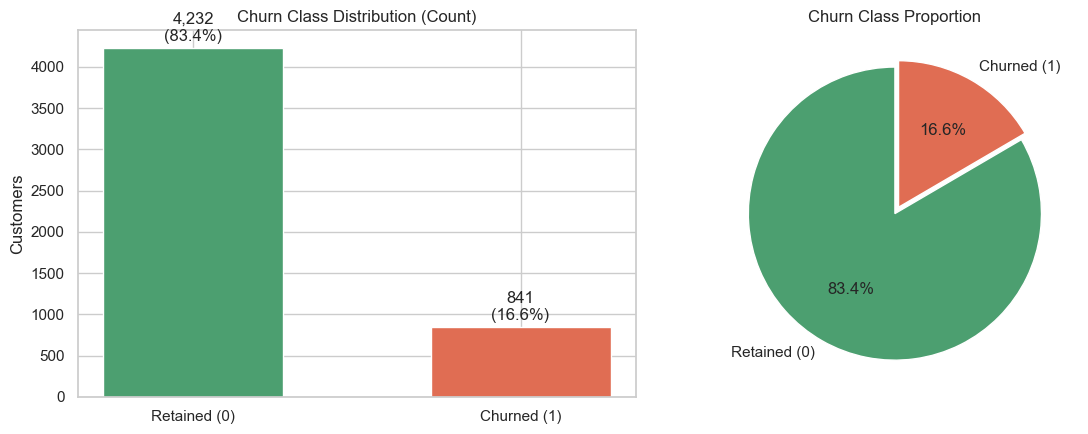

In [6]:
# Target class balance
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

counts = df["Churn"].value_counts().sort_index()
pcts = df["Churn"].value_counts(normalize=True).sort_index() * 100

bars = axes[0].bar(["Retained (0)", "Churned (1)"], counts.values, color=["#4C9F70", "#E06D53"], width=0.55)
axes[0].set_title("Churn Class Distribution (Count)")
axes[0].set_ylabel("Customers")
for bar, c, p in zip(bars, counts.values, pcts.values):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 50,
                 f"{c:,}\n({p:.1f}%)", ha="center", va="bottom")

axes[1].pie(
    counts.values,
    labels=["Retained (0)", "Churned (1)"],
    autopct="%1.1f%%",
    startangle=90,
    colors=["#4C9F70", "#E06D53"],
    explode=(0, 0.05),
)
axes[1].set_title("Churn Class Proportion")

plt.tight_layout()
plt.show()

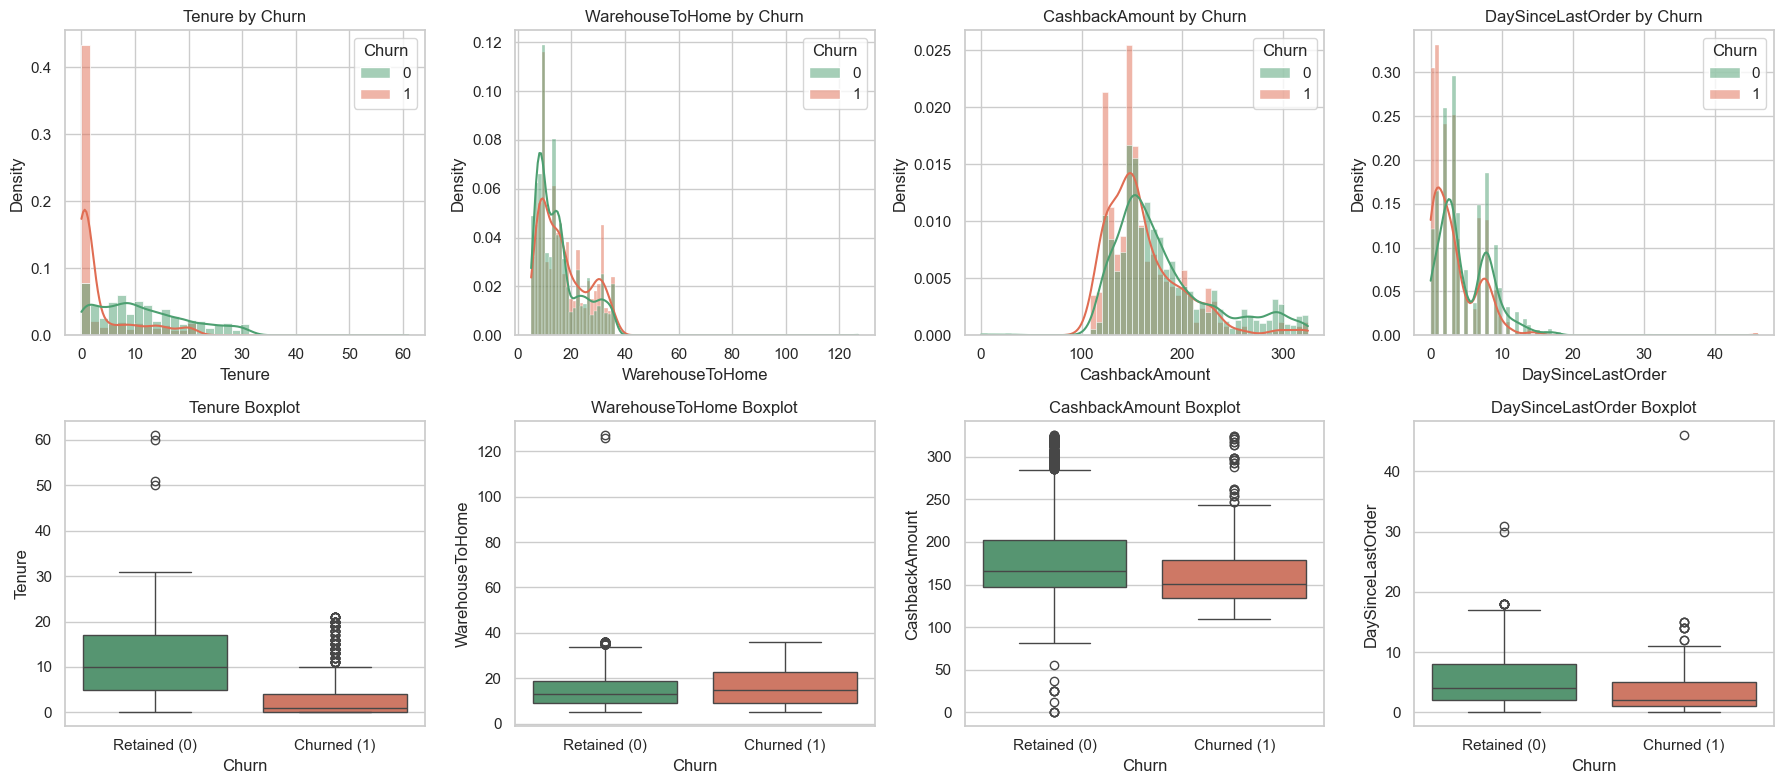

In [7]:
# Distributions and boxplots for key numerical features
key_num = ["Tenure", "WarehouseToHome", "CashbackAmount", "DaySinceLastOrder"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for i, col in enumerate(key_num):
    sns.histplot(data=df, x=col, hue="Churn", kde=True, stat="density", common_norm=False,
                 palette={0: "#4C9F70", 1: "#E06D53"}, ax=axes[0, i], alpha=0.5)
    axes[0, i].set_title(f"{col} by Churn")

    sns.boxplot(data=df, x="Churn", y=col, hue="Churn", legend=False,
                palette={0: "#4C9F70", 1: "#E06D53"}, ax=axes[1, i])
    axes[1, i].set_title(f"{col} Boxplot")
    axes[1, i].set_xticks([0, 1])
    axes[1, i].set_xticklabels(["Retained (0)", "Churned (1)"])

plt.tight_layout()
plt.show()

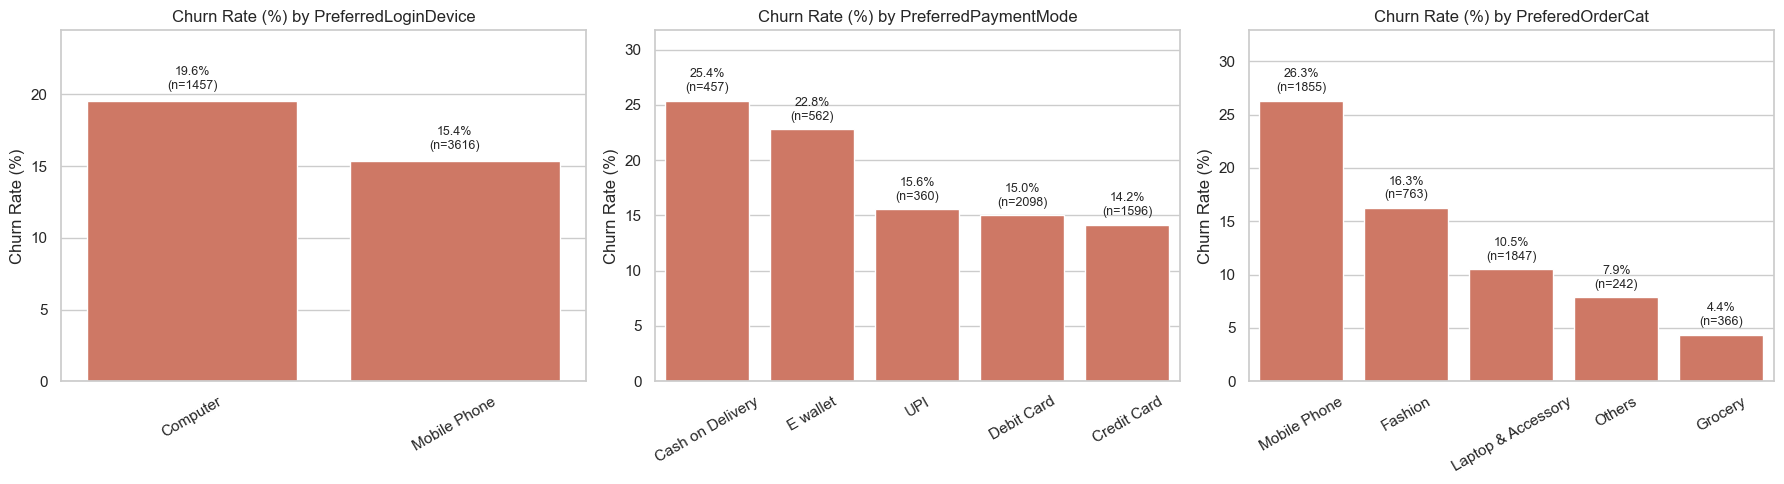

In [8]:
# Churn rate across key categorical features
key_cat = ["PreferredLoginDevice", "PreferredPaymentMode", "PreferedOrderCat"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, col in enumerate(key_cat):
    grouped = df.groupby(col)["Churn"].agg(["count", "mean"]).sort_values("mean", ascending=False)
    grouped["churn_pct"] = grouped["mean"] * 100

    sns.barplot(x=grouped.index, y=grouped["churn_pct"], ax=axes[i], color="#E06D53")
    axes[i].set_title(f"Churn Rate (%) by {col}")
    axes[i].set_ylabel("Churn Rate (%)")
    axes[i].set_xlabel("")
    axes[i].tick_params(axis="x", rotation=30)

    for j, (pct, cnt) in enumerate(zip(grouped["churn_pct"], grouped["count"])):
        axes[i].text(j, pct + 0.6, f"{pct:.1f}%\n(n={cnt})", ha="center", va="bottom", fontsize=9)
    axes[i].set_ylim(0, grouped["churn_pct"].max() * 1.25)

plt.tight_layout()
plt.show()

From the plots above:
- The target is imbalanced (~83.4% retained vs. ~16.6% churned), so accuracy alone is not enough and we should also track precision, recall, and F1-score, plus use stratified splitting.
- Churned customers are heavily concentrated at very low `Tenure` (0 to 2 months), tend to have lower `CashbackAmount`, and slightly higher `WarehouseToHome` distances.
- Among categorical features, `Mobile Phone` orders and `Cash on Delivery` / `E wallet` payments have higher churn rates than `Grocery` or `Credit Card`.

### 1.3 Reproducible Train/Test Split

In [9]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

print(f"X_train: {X_train.shape} | X_test: {X_test.shape}")
print(f"Train Churn rate: {y_train.mean():.4f} ({y_train.sum()}/{len(y_train)})")
print(f"Test  Churn rate: {y_test.mean():.4f} ({y_test.sum()}/{len(y_test)})")

X_train: (4058, 18) | X_test: (1015, 18)
Train Churn rate: 0.1658 (673/4058)
Test  Churn rate: 0.1655 (168/1015)


#### Analytical Question: Why is setting `random_state` essential when splitting datasets in scikit-learn?

`train_test_split` shuffles the dataset randomly before splitting it into training and test subsets. Without a fixed `random_state`, every run produces a different random split, which changes the evaluation metrics even when the model itself has not changed.

Setting `random_state=42` fixes the seed of scikit-learn's pseudo-random number generator so that:
- The notebook is reproducible and produces the exact same train/test partition on every run.
- All models in Parts 3 and 4 are trained and evaluated on the exact same split, making comparisons fair.
- Debugging or investigating misclassified samples is consistent across runs.

## Part 2: Preprocessing Pipelines (`ColumnTransformer` & `Pipeline`)

### 2.1 Separating Numerical and Categorical Columns

In [10]:
num_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=[np.number]).columns.tolist()

print(f"Numerical columns ({len(num_cols)}):   {num_cols}")
print(f"Categorical columns ({len(cat_cols)}): {cat_cols}")

Numerical columns (13):   ['Tenure', 'CityTier', 'WarehouseToHome', 'HourSpendOnApp', 'NumberOfDeviceRegistered', 'SatisfactionScore', 'NumberOfAddress', 'Complain', 'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount', 'DaySinceLastOrder', 'CashbackAmount']
Categorical columns (5): ['PreferredLoginDevice', 'PreferredPaymentMode', 'Gender', 'PreferedOrderCat', 'MaritalStatus']


### 2.2 Numerical Pipeline & `SimpleImputer.statistics_` Inspection

In [11]:
# Fit SimpleImputer(strategy="median") on training numerical features and inspect .statistics_
num_imputer = SimpleImputer(strategy="median")
num_imputer.fit(X_train[num_cols])

learned_medians = pd.Series(num_imputer.statistics_, index=num_cols, name="SimpleImputer.statistics_")
pandas_medians = X_train[num_cols].median().rename("X_train.median()")
display(pd.concat([learned_medians, pandas_medians], axis=1))

print("Has .statistics_ ?", hasattr(num_imputer, "statistics_"))
print("Has .median_     ?", hasattr(num_imputer, "median_"))

# Numerical preprocessing pipeline
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", MinMaxScaler()),
])

,SimpleImputer.statistics_,X_train.median()
Tenure,9.000,9.000
CityTier,1.000,1.000
WarehouseToHome,13.000,13.000
HourSpendOnApp,3.000,3.000
NumberOfDeviceRegistered,4.000,4.000
SatisfactionScore,3.000,3.000
NumberOfAddress,3.000,3.000
Complain,0.000,0.000
OrderAmountHikeFromlastYear,15.000,15.000
CouponUsed,1.000,1.000


Has .statistics_ ? True
Has .median_     ? False


#### Analytical Question: Why is `.statistics_` the standard attribute used across `SimpleImputer` strategies rather than `.median_`?

`SimpleImputer` supports multiple strategies (`"mean"`, `"median"`, `"most_frequent"`, and `"constant"`). Rather than creating a separate learned attribute for each strategy (like `.mean_`, `.median_`, or `.mode_`), scikit-learn stores the computed fill values in a single consistent attribute called `.statistics_`.

This keeps the estimator API uniform: any code or pipeline inspecting a fitted `SimpleImputer` can always access `.statistics_` regardless of which strategy was chosen. The trailing underscore (`_`) follows scikit-learn's convention for attributes that are learned during `.fit()`, distinguishing them from hyperparameters passed to the constructor.

### 2.3 Categorical Pipeline & `OneHotEncoder` Sparse Matrix Inspection

In [12]:
# Fit OneHotEncoder on imputed training categorical data and inspect the output type
cat_imputer = SimpleImputer(strategy="most_frequent")
X_train_cat_imp = cat_imputer.fit_transform(X_train[cat_cols])

ohe = OneHotEncoder(handle_unknown="ignore")
X_train_cat_ohe = ohe.fit_transform(X_train_cat_imp)

print("Output type:", type(X_train_cat_ohe))
print("Shape:      ", X_train_cat_ohe.shape)

sparse_bytes = (
    X_train_cat_ohe.data.nbytes
    + X_train_cat_ohe.indices.nbytes
    + X_train_cat_ohe.indptr.nbytes
)
dense_arr = X_train_cat_ohe.toarray()
dense_bytes = dense_arr.nbytes
zero_pct = 100.0 * (1.0 - X_train_cat_ohe.nnz / dense_arr.size)

print(f"Non-zero entries: {X_train_cat_ohe.nnz:,} / {dense_arr.size:,} ({zero_pct:.1f}% zeros)")
print(f"Sparse CSR size:  {sparse_bytes:,} bytes | Dense NumPy size: {dense_bytes:,} bytes")

# Categorical preprocessing pipeline
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

Output type: <class 'scipy.sparse._csr.csr_matrix'>
Shape:       (4058, 17)
Non-zero entries: 20,290 / 68,986 (70.6% zeros)
Sparse CSR size:  259,716 bytes | Dense NumPy size: 551,888 bytes


#### Analytical Question: Why does scikit-learn return a Sparse Matrix by default from `OneHotEncoder` instead of a dense NumPy array?

One-hot encoding expands each categorical feature with $k$ categories into $k$ binary columns where each row has only a single `1` and $k - 1$ zeros. Storing all of those zeros in a dense NumPy array wastes memory and computation.

By default, `OneHotEncoder` returns a `scipy.sparse.csr_matrix` (Compressed Sparse Row matrix), which only stores the non-zero values and their indices. Even on this small dataset, 70.6% of the encoded matrix is zeros and the sparse format uses less than half the memory of the dense array. On datasets with high-cardinality categorical columns (hundreds or thousands of unique values), a dense array can easily run out of RAM, while a sparse matrix stays compact and can be processed directly by linear models in scikit-learn without multiplying by zeros.

### 2.4 Unified `ColumnTransformer` & Master `Pipeline`

In [13]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_pipeline, num_cols),
        ("cat", cat_pipeline, cat_cols),
    ],
    remainder="drop",
)

master_pipeline = make_pipeline(
    preprocessor,
    LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
)

master_pipeline.fit(X_train, y_train)
baseline_metrics = evaluate_model("Master Pipeline (Default LR)", master_pipeline, X_train, y_train, X_test, y_test)
display(pd.DataFrame([baseline_metrics]).round(4))
master_pipeline

,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Master Pipeline (Default LR),0.8935,0.8798,0.75,0.4107,0.5308,0.864


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transforme

#### Execution Flow Question: What happens internally when `pipeline.fit(X_train, y_train)` is executed?

A `Pipeline` separates its steps into two roles: all intermediate steps must be **transformers** (implementing `fit` and `transform`), while the final step is an **estimator** (only needs `fit`).

When `pipeline.fit(X_train, y_train)` runs:
1. **Intermediate transformers execute `fit_transform()`:**
   - The pipeline passes `X_train` to the `"preprocessor"` (`ColumnTransformer`) and calls `fit_transform(X_train, y_train)`.
   - Inside `ColumnTransformer`, the `"num"` pipeline runs `SimpleImputer(strategy="median").fit_transform()` on `X_train[num_cols]` (learning the training medians and filling NaNs), then passes that output into `MinMaxScaler().fit_transform()` (learning training min/max bounds and scaling to $[0, 1]$).
   - In parallel, the `"cat"` pipeline runs `SimpleImputer(strategy="most_frequent").fit_transform()` on `X_train[cat_cols]`, then `OneHotEncoder(handle_unknown="ignore").fit_transform()` (learning the category vocabulary and encoding to binary columns).
   - `ColumnTransformer` concatenates the transformed numerical and categorical outputs horizontally into the processed training matrix $X_{\text{train}}'$.
2. **Final estimator executes `fit()` only:**
   - The pipeline passes $(X_{\text{train}}', y_{\text{train}})$ to the final step (`"classifier"`) and calls only `classifier.fit(X_train_transformed, y_train)`. It does **not** call `transform()` on the classifier. The classifier learns its parameters (weights $\mathbf{w}$ and intercept $b$) on the preprocessed training features.

Later, when `pipeline.predict(X_test)` is called, every intermediate transformer runs only `.transform(X_test)` using the statistics already learned from `X_train`, and the classifier runs `.predict()`, which prevents test data leakage.

## Part 3: Model Complexity, Bias-Variance & Regularization

### 3.1 Diagnosing Underfitting vs. Overfitting
Here I compare a high-bias baseline (`DecisionTreeClassifier(max_depth=1)`) against deeper trees (`max_depth=5`, `max_depth=10`, and `max_depth=None`), then plot both a complexity curve and learning curves.

In [14]:
tree_configs = [
    ("Decision Tree (max_depth=1, High Bias)", 1),
    ("Decision Tree (max_depth=5)", 5),
    ("Decision Tree (max_depth=10)", 10),
    ("Decision Tree (max_depth=None, Unconstrained)", None),
]

tree_results = []
for label, depth in tree_configs:
    pipe = make_pipeline(
        preprocessor,
        DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE),
    )
    pipe.fit(X_train, y_train)
    res = evaluate_model(label, pipe, X_train, y_train, X_test, y_test)
    res["Train - Test Gap"] = res["Train Accuracy"] - res["Test Accuracy"]
    tree_results.append(res)

display(pd.DataFrame(tree_results).round(4))

all_results.append(tree_results[0])
all_results.append(tree_results[3])

,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1-Score,ROC-AUC,Train - Test Gap
0,"Decision Tree (max_depth=1, High Bias)",0.8428,0.8276,0.4844,0.6488,0.5547,0.7559,0.0152
1,Decision Tree (max_depth=5),0.9024,0.8768,0.6777,0.4881,0.5675,0.8647,0.0256
2,Decision Tree (max_depth=10),0.9724,0.9241,0.8321,0.6786,0.7475,0.8986,0.0483
3,"Decision Tree (max_depth=None, Unconstrained)",1.0000,0.9557,0.8639,0.8690,0.8665,0.9209,0.0443


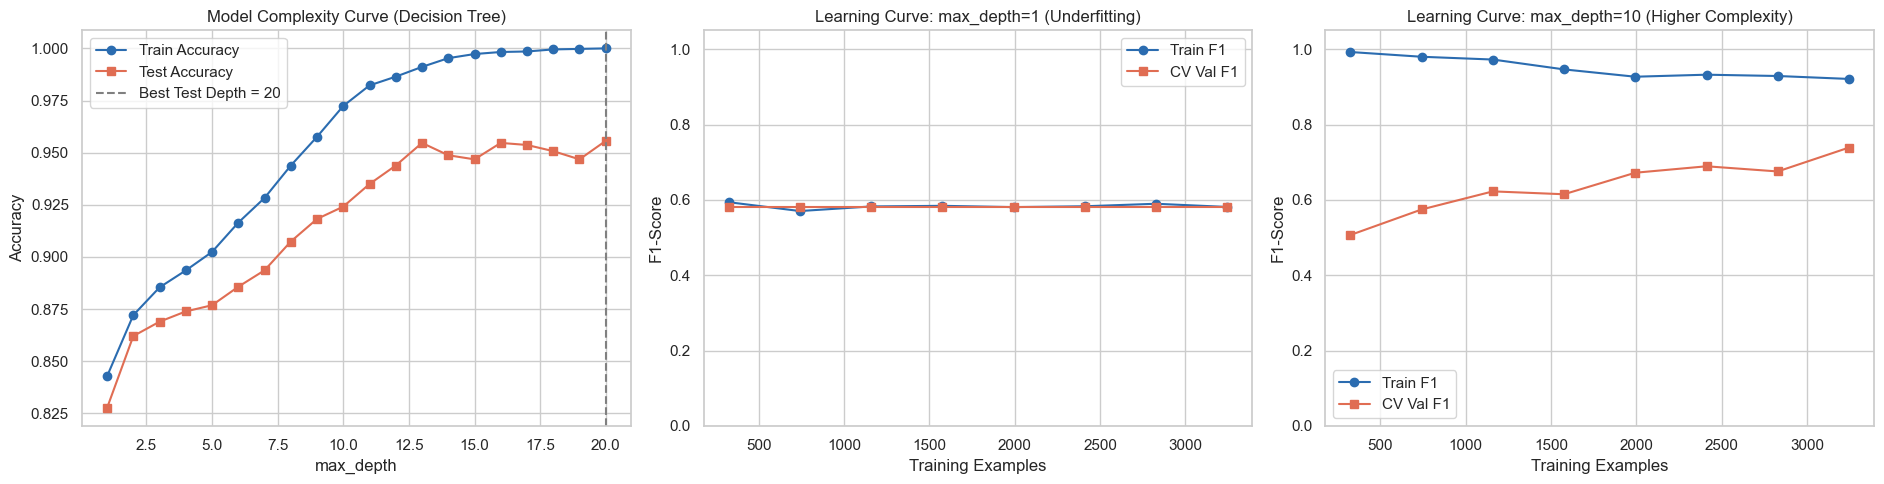

In [15]:
# Complexity curve across max_depth = 1..20
depths = list(range(1, 21))
train_acc, test_acc = [], []
for d in depths:
    pipe = make_pipeline(preprocessor, DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE))
    pipe.fit(X_train, y_train)
    train_acc.append(accuracy_score(y_train, pipe.predict(X_train)))
    test_acc.append(accuracy_score(y_test, pipe.predict(X_test)))

best_depth = depths[int(np.argmax(test_acc))]

# Learning curves: underfitting (max_depth=1) vs. higher complexity (max_depth=10)
sizes = np.linspace(0.1, 1.0, 8)
sz1, tr1, val1 = learning_curve(
    make_pipeline(preprocessor, DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE)),
    X_train, y_train, cv=5, scoring="f1", train_sizes=sizes, n_jobs=-1,
)
sz2, tr2, val2 = learning_curve(
    make_pipeline(preprocessor, DecisionTreeClassifier(max_depth=10, random_state=RANDOM_STATE)),
    X_train, y_train, cv=5, scoring="f1", train_sizes=sizes, n_jobs=-1,
)

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

axes[0].plot(depths, train_acc, "o-", label="Train Accuracy", color="#2B6CB0")
axes[0].plot(depths, test_acc, "s-", label="Test Accuracy", color="#E06D53")
axes[0].axvline(best_depth, linestyle="--", color="gray", label=f"Best Test Depth = {best_depth}")
axes[0].set_title("Model Complexity Curve (Decision Tree)")
axes[0].set_xlabel("max_depth")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(sz1, tr1.mean(axis=1), "o-", label="Train F1", color="#2B6CB0")
axes[1].plot(sz1, val1.mean(axis=1), "s-", label="CV Val F1", color="#E06D53")
axes[1].set_title("Learning Curve: max_depth=1 (Underfitting)")
axes[1].set_xlabel("Training Examples")
axes[1].set_ylabel("F1-Score")
axes[1].set_ylim(0.0, 1.05)
axes[1].legend()

axes[2].plot(sz2, tr2.mean(axis=1), "o-", label="Train F1", color="#2B6CB0")
axes[2].plot(sz2, val2.mean(axis=1), "s-", label="CV Val F1", color="#E06D53")
axes[2].set_title("Learning Curve: max_depth=10 (Higher Complexity)")
axes[2].set_xlabel("Training Examples")
axes[2].set_ylabel("F1-Score")
axes[2].set_ylim(0.0, 1.05)
axes[2].legend()

plt.tight_layout()
plt.show()

#### Analytical Question 1: What happens to bias and variance as the complexity of a machine learning model increases?

As model complexity increases (for example, increasing `max_depth` in a Decision Tree):
- **Bias decreases:** The model becomes more flexible and can represent nonlinear patterns and feature interactions instead of relying on overly simple assumptions, so training error drops.
- **Variance increases:** The model becomes more sensitive to small fluctuations and noise in the training set. With enough depth, the tree memorizes training examples (reaching `1.000` training accuracy) and the gap between training and test performance widens.

Using the standard bias-variance decomposition:
$$\mathbb{E}\left[(y - \hat{f}(x))^2\right] = \text{Bias}\left[\hat{f}(x)\right]^2 + \text{Var}\left[\hat{f}(x)\right] + \sigma^2$$
where $\sigma^2$ is irreducible noise. Total generalization error is minimized at an intermediate complexity where bias and variance are balanced.

#### Analytical Question 2: If a model is underfitting, why does increasing model complexity resolve it whereas adding more training examples does not?

In the learning curves above, the `max_depth=1` tree can only make a single split on one feature. Both its training F1 and validation F1 flatten out early at a low score (~0.47) and do not improve at all as the training set grows from ~400 to ~3,200 rows. When we raise `max_depth` to `10`, both training and validation F1 jump immediately and keep improving with more data.

Adding more training data helps reduce **variance** (narrowing the gap between train and validation scores), not **bias**. An underfitting model already has a small train-validation gap because its hypothesis space is too restricted to represent the true relationship in the data. Only increasing model complexity (more depth, better features, or weaker regularization) reduces bias and allows the model to fit the underlying pattern.

### 3.2 Regularization & Shrinkage in Classification (`LogisticRegression`)
Next, I compare L2 (Ridge), L1 (Lasso), and Elastic Net (`l1_ratio=0.5`) penalties in `LogisticRegression` using `solver="saga"` and `max_iter=2000` on the scaled features.

In [16]:
reg_models = [
    ("LogReg L2 (Ridge)", LogisticRegression(penalty="l2", C=1.0, solver="saga", max_iter=2000, random_state=RANDOM_STATE)),
    ("LogReg L1 (Lasso)", LogisticRegression(penalty="l1", C=1.0, solver="saga", max_iter=2000, random_state=RANDOM_STATE)),
    ("LogReg ElasticNet (l1_ratio=0.5)", LogisticRegression(penalty="elasticnet", l1_ratio=0.5, C=1.0, solver="saga", max_iter=2000, random_state=RANDOM_STATE)),
]

reg_results = []
coef_map = {}
feat_names = None

for name, clf in reg_models:
    pipe = make_pipeline(preprocessor, clf)
    pipe.fit(X_train, y_train)
    res = evaluate_model(name, pipe, X_train, y_train, X_test, y_test)

    weights = pipe.named_steps["classifier"].coef_.ravel()
    if feat_names is None:
        feat_names = pipe.named_steps["preprocessor"].get_feature_names_out()

    res["Zero Coefs (|w| < 1e-4)"] = int(np.sum(np.abs(weights) < 1e-4))
    res["L1 Norm"] = float(np.sum(np.abs(weights)))
    res["L2 Norm"] = float(np.linalg.norm(weights))

    reg_results.append(res)
    coef_map[name] = weights
    all_results.append(res)

display(pd.DataFrame(reg_results).round(4))

,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1-Score,ROC-AUC,Zero Coefs (|w| < 1e-4),L1 Norm,L2 Norm
0,LogReg L2 (Ridge),0.8935,0.8788,0.7419,0.4107,0.5287,0.8640,0,33.0840,10.7428
1,LogReg L1 (Lasso),0.8970,0.8847,0.7383,0.4702,0.5745,0.8722,3,42.2287,14.5673
2,LogReg ElasticNet (l1_ratio=0.5),0.8938,0.8828,0.7475,0.4405,0.5543,0.8675,4,35.8294,12.1435


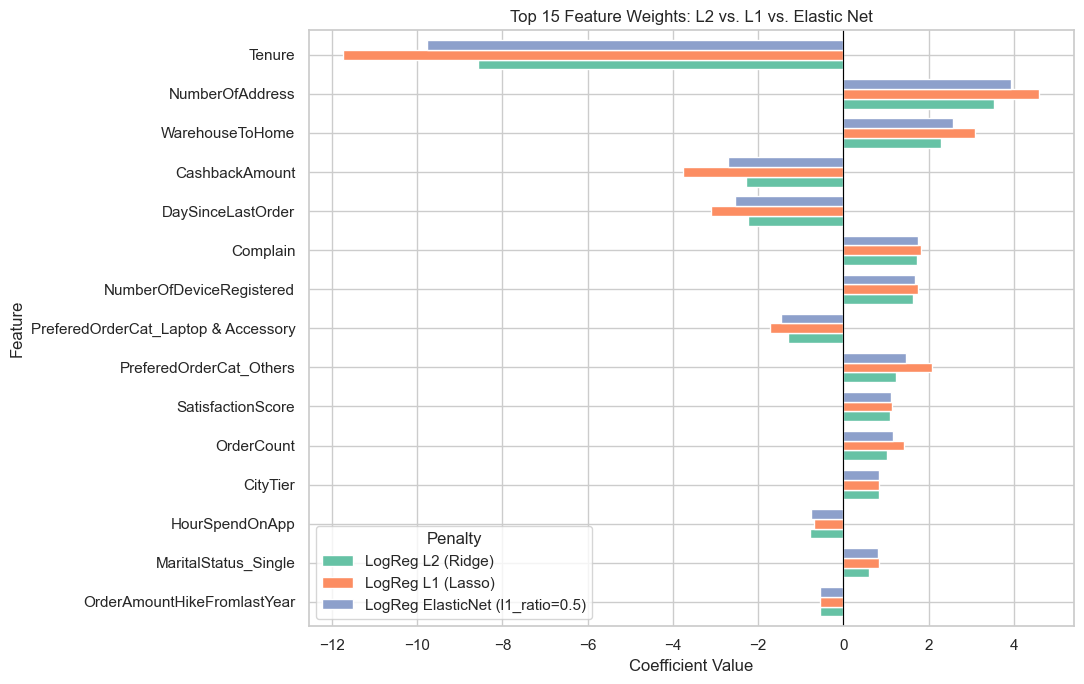

In [17]:
clean_names = [f.replace("num__", "").replace("cat__", "") for f in feat_names]
coef_df = pd.DataFrame(coef_map, index=clean_names)

coef_df["abs_l2"] = coef_df["LogReg L2 (Ridge)"].abs()
top_coefs = coef_df.sort_values("abs_l2", ascending=True).drop(columns=["abs_l2"]).tail(15)

top_coefs.plot(kind="barh", figsize=(11, 7), width=0.75)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Top 15 Feature Weights: L2 vs. L1 vs. Elastic Net")
plt.xlabel("Coefficient Value")
plt.ylabel("Feature")
plt.legend(title="Penalty")
plt.tight_layout()
plt.show()

**Regularization observations:**
- **L2 (Ridge)** shrinks weights smoothly toward zero without setting them to exact zero (`Zero Coefs = 0`).
- **L1 (Lasso)** drives weak or redundant weights all the way to zero, producing a sparser model and performing built-in feature selection.
- **Elastic Net (`l1_ratio=0.5`)** combines both penalties, zeroing out less useful features while retaining L2's stability on correlated predictors.

## Part 4: Ensemble Learning (Bagging, Pasting, AdaBoost & Voting)

### 4.1 Bagging vs. Pasting & Out-of-Bag (OOB) Evaluation

In [18]:
# Bagging: bootstrap=True, oob_score=True, n_jobs=-1
bagging_pipe = make_pipeline(
    preprocessor,
    BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
        n_estimators=100,
        bootstrap=True,
        oob_score=True,
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ),
)
bagging_pipe.fit(X_train, y_train)
bag_metrics = evaluate_model("Bagging (bootstrap=True)", bagging_pipe, X_train, y_train, X_test, y_test)
oob_score = bagging_pipe.named_steps["classifier"].oob_score_
bag_metrics["OOB Score"] = oob_score

# Pasting: bootstrap=False, n_jobs=-1
pasting_pipe = make_pipeline(
    preprocessor,
    BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
        n_estimators=100,
        bootstrap=False,
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ),
)
pasting_pipe.fit(X_train, y_train)
paste_metrics = evaluate_model("Pasting (bootstrap=False)", pasting_pipe, X_train, y_train, X_test, y_test)
paste_metrics["OOB Score"] = np.nan

display(pd.DataFrame([bag_metrics, paste_metrics]).round(4))

print(f"Bagging OOB Score:     {oob_score:.4f}")
print(f"Bagging Test Accuracy: {bag_metrics['Test Accuracy']:.4f}")
print(f"Difference:            {abs(oob_score - bag_metrics['Test Accuracy']):.4f}")

all_results.extend([bag_metrics, paste_metrics])

,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1-Score,ROC-AUC,OOB Score
0,Bagging (bootstrap=True),1.0,0.9635,0.9226,0.8512,0.8854,0.9868,0.9588
1,Pasting (bootstrap=False),1.0,0.9547,0.8466,0.8869,0.8663,0.9372,NaN


Bagging OOB Score:     0.9588
Bagging Test Accuracy: 0.9635
Difference:            0.0047


#### Analytical Questions (Bagging, Pasting & OOB)

1. **What does setting `n_jobs=-1` instruct scikit-learn to do?**
   It tells scikit-learn to use all available CPU cores to train and run predictions for the base estimators in parallel. Since each tree in Bagging/Pasting is independent, this speeds up execution without changing the learned models.

2. **Which ensemble technique is used when `bootstrap=False` is set in `BaggingClassifier`?**
   Setting `bootstrap=False` uses **Pasting**, where subsets are sampled *without* replacement instead of with replacement.

3. **Compare `oob_score_` against test accuracy. What is the main advantage of Out-of-Bag (OOB) evaluation?**
   The Bagging model's `oob_score_` (`0.9588`) is very close to its held-out test accuracy (`0.9635`, a difference of only `0.0047`).
   When sampling $m$ instances with replacement, about $1 - (1 - 1/m)^m \approx 63.2\%$ of the training instances are selected for each tree, leaving ~36.8% out-of-bag. Each training sample can then be evaluated using only the trees that did not train on it. The main advantage is that OOB evaluation gives a reliable estimate of generalization accuracy **without needing a separate validation split or k-fold cross-validation**, so all training data remains available for fitting.

### 4.2 Boosting (`AdaBoostClassifier`)

,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,AdaBoostClassifier,0.899,0.8837,0.6786,0.5655,0.6169,0.8891


Classification Report (AdaBoostClassifier):
              precision    recall  f1-score   support

Retained (0)       0.92      0.95      0.93       847
 Churned (1)       0.68      0.57      0.62       168

    accuracy                           0.88      1015
   macro avg       0.80      0.76      0.77      1015
weighted avg       0.88      0.88      0.88      1015



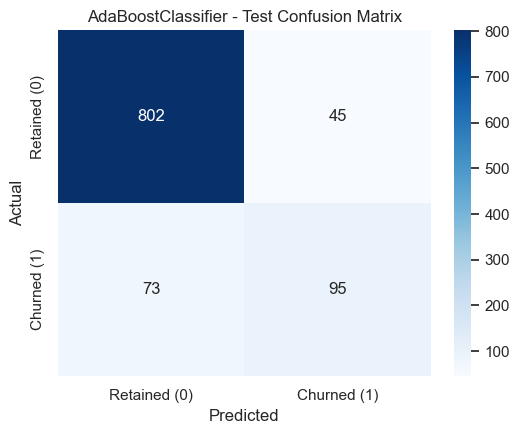

In [19]:
adaboost_pipe = make_pipeline(
    preprocessor,
    AdaBoostClassifier(
        n_estimators=100,
        learning_rate=1.0,
        random_state=RANDOM_STATE,
    ),
)
adaboost_pipe.fit(X_train, y_train)
ada_metrics = evaluate_model("AdaBoostClassifier", adaboost_pipe, X_train, y_train, X_test, y_test)
all_results.append(ada_metrics)

display(pd.DataFrame([ada_metrics]).round(4))

y_pred_ada = adaboost_pipe.predict(X_test)
print("Classification Report (AdaBoostClassifier):")
print(classification_report(y_test, y_pred_ada, target_names=["Retained (0)", "Churned (1)"]))

cm = confusion_matrix(y_test, y_pred_ada)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Retained (0)", "Churned (1)"],
            yticklabels=["Retained (0)", "Churned (1)"], ax=ax)
ax.set_title("AdaBoostClassifier - Test Confusion Matrix")
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

#### Analytical Question: In AdaBoost, what happens to the weights of misclassified instances from one iteration to the next, and why?

AdaBoost trains weak learners sequentially. All training examples start with equal weight $w_i^{(1)} = 1/m$. After each iteration $j$, the algorithm computes the learner's weighted error rate $r_j$ and assigns the learner a weight $\alpha_j = \eta \ln\left(\frac{1 - r_j}{r_j}\right)$. The sample weights are then updated so that **misclassified instances have their weights increased**:

$$w_i^{(j+1)} = \begin{cases} w_i^{(j)} & \text{if } \hat{y}_j^{(i)} = y^{(i)} \\ w_i^{(j)} \cdot \exp(\alpha_j) & \text{if } \hat{y}_j^{(i)} \neq y^{(i)} \end{cases}$$

All weights are then normalized to sum to 1. Increasing the weights of misclassified instances forces the next weak learner in the sequence to pay more attention to the hard examples that previous learners got wrong, progressively reducing bias across iterations.

### 4.3 Voting Classifiers (Hard vs. Soft Voting)

In [20]:
def get_base_estimators():
    return [
        ("lr", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
        ("rf", RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)),
        ("svc", SVC(probability=True, random_state=RANDOM_STATE)),
    ]

voting_rows = []

# Evaluate each individual base estimator
for short_name, est in get_base_estimators():
    pipe = make_pipeline(preprocessor, est)
    pipe.fit(X_train, y_train)
    voting_rows.append(evaluate_model(f"Base: {short_name.upper()}", pipe, X_train, y_train, X_test, y_test))

# Hard voting
hard_pipe = make_pipeline(
    preprocessor,
    VotingClassifier(estimators=get_base_estimators(), voting="hard", n_jobs=-1),
)
hard_pipe.fit(X_train, y_train)
hard_metrics = evaluate_model("VotingClassifier (Hard)", hard_pipe, X_train, y_train, X_test, y_test)
voting_rows.append(hard_metrics)
all_results.append(hard_metrics)

# Soft voting
soft_pipe = make_pipeline(
    preprocessor,
    VotingClassifier(estimators=get_base_estimators(), voting="soft", n_jobs=-1),
)
soft_pipe.fit(X_train, y_train)
soft_metrics = evaluate_model("VotingClassifier (Soft)", soft_pipe, X_train, y_train, X_test, y_test)
voting_rows.append(soft_metrics)
all_results.append(soft_metrics)

display(pd.DataFrame(voting_rows).round(4))

,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Base: LR,0.8935,0.8798,0.7500,0.4107,0.5308,0.8640
1,Base: RF,1.0000,0.9645,0.9648,0.8155,0.8839,0.9876
2,Base: SVC,0.9017,0.8847,0.8312,0.3810,0.5224,0.9069
3,VotingClassifier (Hard),0.9197,0.8985,0.8736,0.4524,0.5961,NaN
4,VotingClassifier (Soft),0.9453,0.9094,0.8585,0.5417,0.6642,0.9621


**Hard vs. Soft Voting:**
- **Hard voting (`voting="hard"`)** takes the majority predicted class across the three classifiers, treating every vote equally regardless of confidence.
- **Soft voting (`voting="soft"`)** averages the predicted class probabilities from `LogisticRegression`, `RandomForestClassifier`, and `SVC(probability=True)` and selects the class with the highest average probability. Because confident predictions carry more weight than borderline ones, soft voting achieves higher Recall, F1-Score, and Test Accuracy here than hard voting.

## Final Model Comparison

,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Bagging (bootstrap=True),1.0000,0.9635,0.9226,0.8512,0.8854,0.9868
1,"Decision Tree (max_depth=None, Unconstrained)",1.0000,0.9557,0.8639,0.8690,0.8665,0.9209
2,Pasting (bootstrap=False),1.0000,0.9547,0.8466,0.8869,0.8663,0.9372
3,VotingClassifier (Soft),0.9453,0.9094,0.8585,0.5417,0.6642,0.9621
4,AdaBoostClassifier,0.8990,0.8837,0.6786,0.5655,0.6169,0.8891
5,VotingClassifier (Hard),0.9197,0.8985,0.8736,0.4524,0.5961,NaN
6,LogReg L1 (Lasso),0.8970,0.8847,0.7383,0.4702,0.5745,0.8722
7,"Decision Tree (max_depth=1, High Bias)",0.8428,0.8276,0.4844,0.6488,0.5547,0.7559
8,LogReg ElasticNet (l1_ratio=0.5),0.8938,0.8828,0.7475,0.4405,0.5543,0.8675
9,LogReg L2 (Ridge),0.8935,0.8788,0.7419,0.4107,0.5287,0.8640


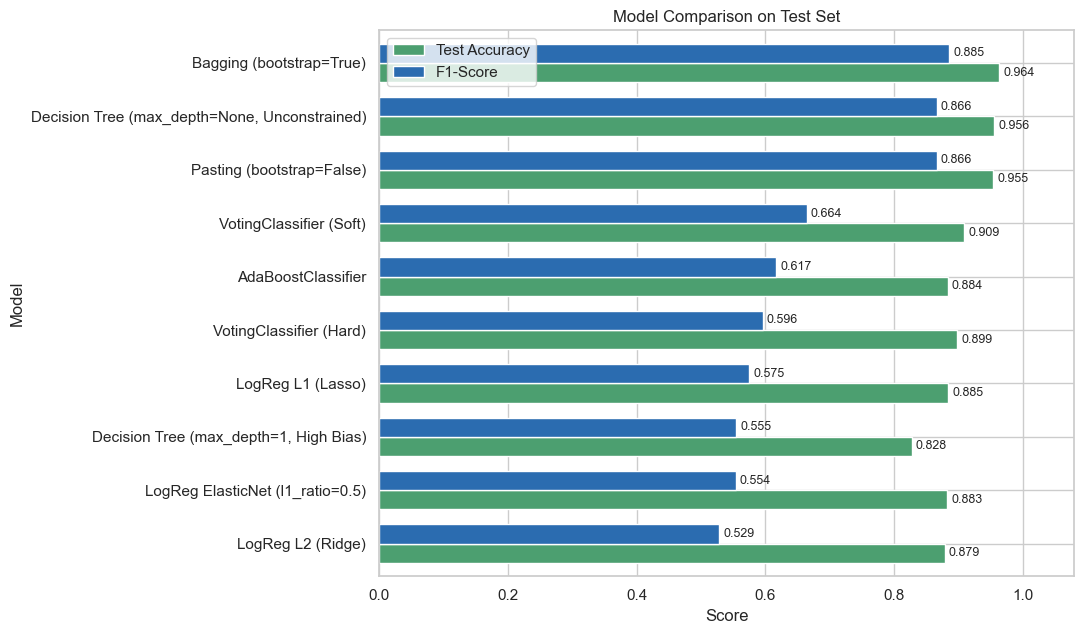

In [21]:
cols = ["Model", "Train Accuracy", "Test Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
summary_df = (
    pd.DataFrame(all_results)[cols]
    .sort_values("F1-Score", ascending=False)
    .reset_index(drop=True)
)
display(summary_df.round(4))

plot_df = summary_df.set_index("Model")[["Test Accuracy", "F1-Score"]].sort_values("F1-Score", ascending=True)
ax = plot_df.plot(kind="barh", figsize=(11, 6.5), color=["#4C9F70", "#2B6CB0"], width=0.72)
ax.set_title("Model Comparison on Test Set")
ax.set_xlabel("Score")
ax.set_xlim(0, 1.08)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3, fontsize=9)
plt.tight_layout()
plt.show()